In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from sklearn.decomposition import PCA

%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [2]:
df = pd.read_csv('housing.csv.zip')

In [3]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [5]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [6]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [7]:
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [8]:
num_cols=[col for col in df.columns if df[col].dtype!='0']

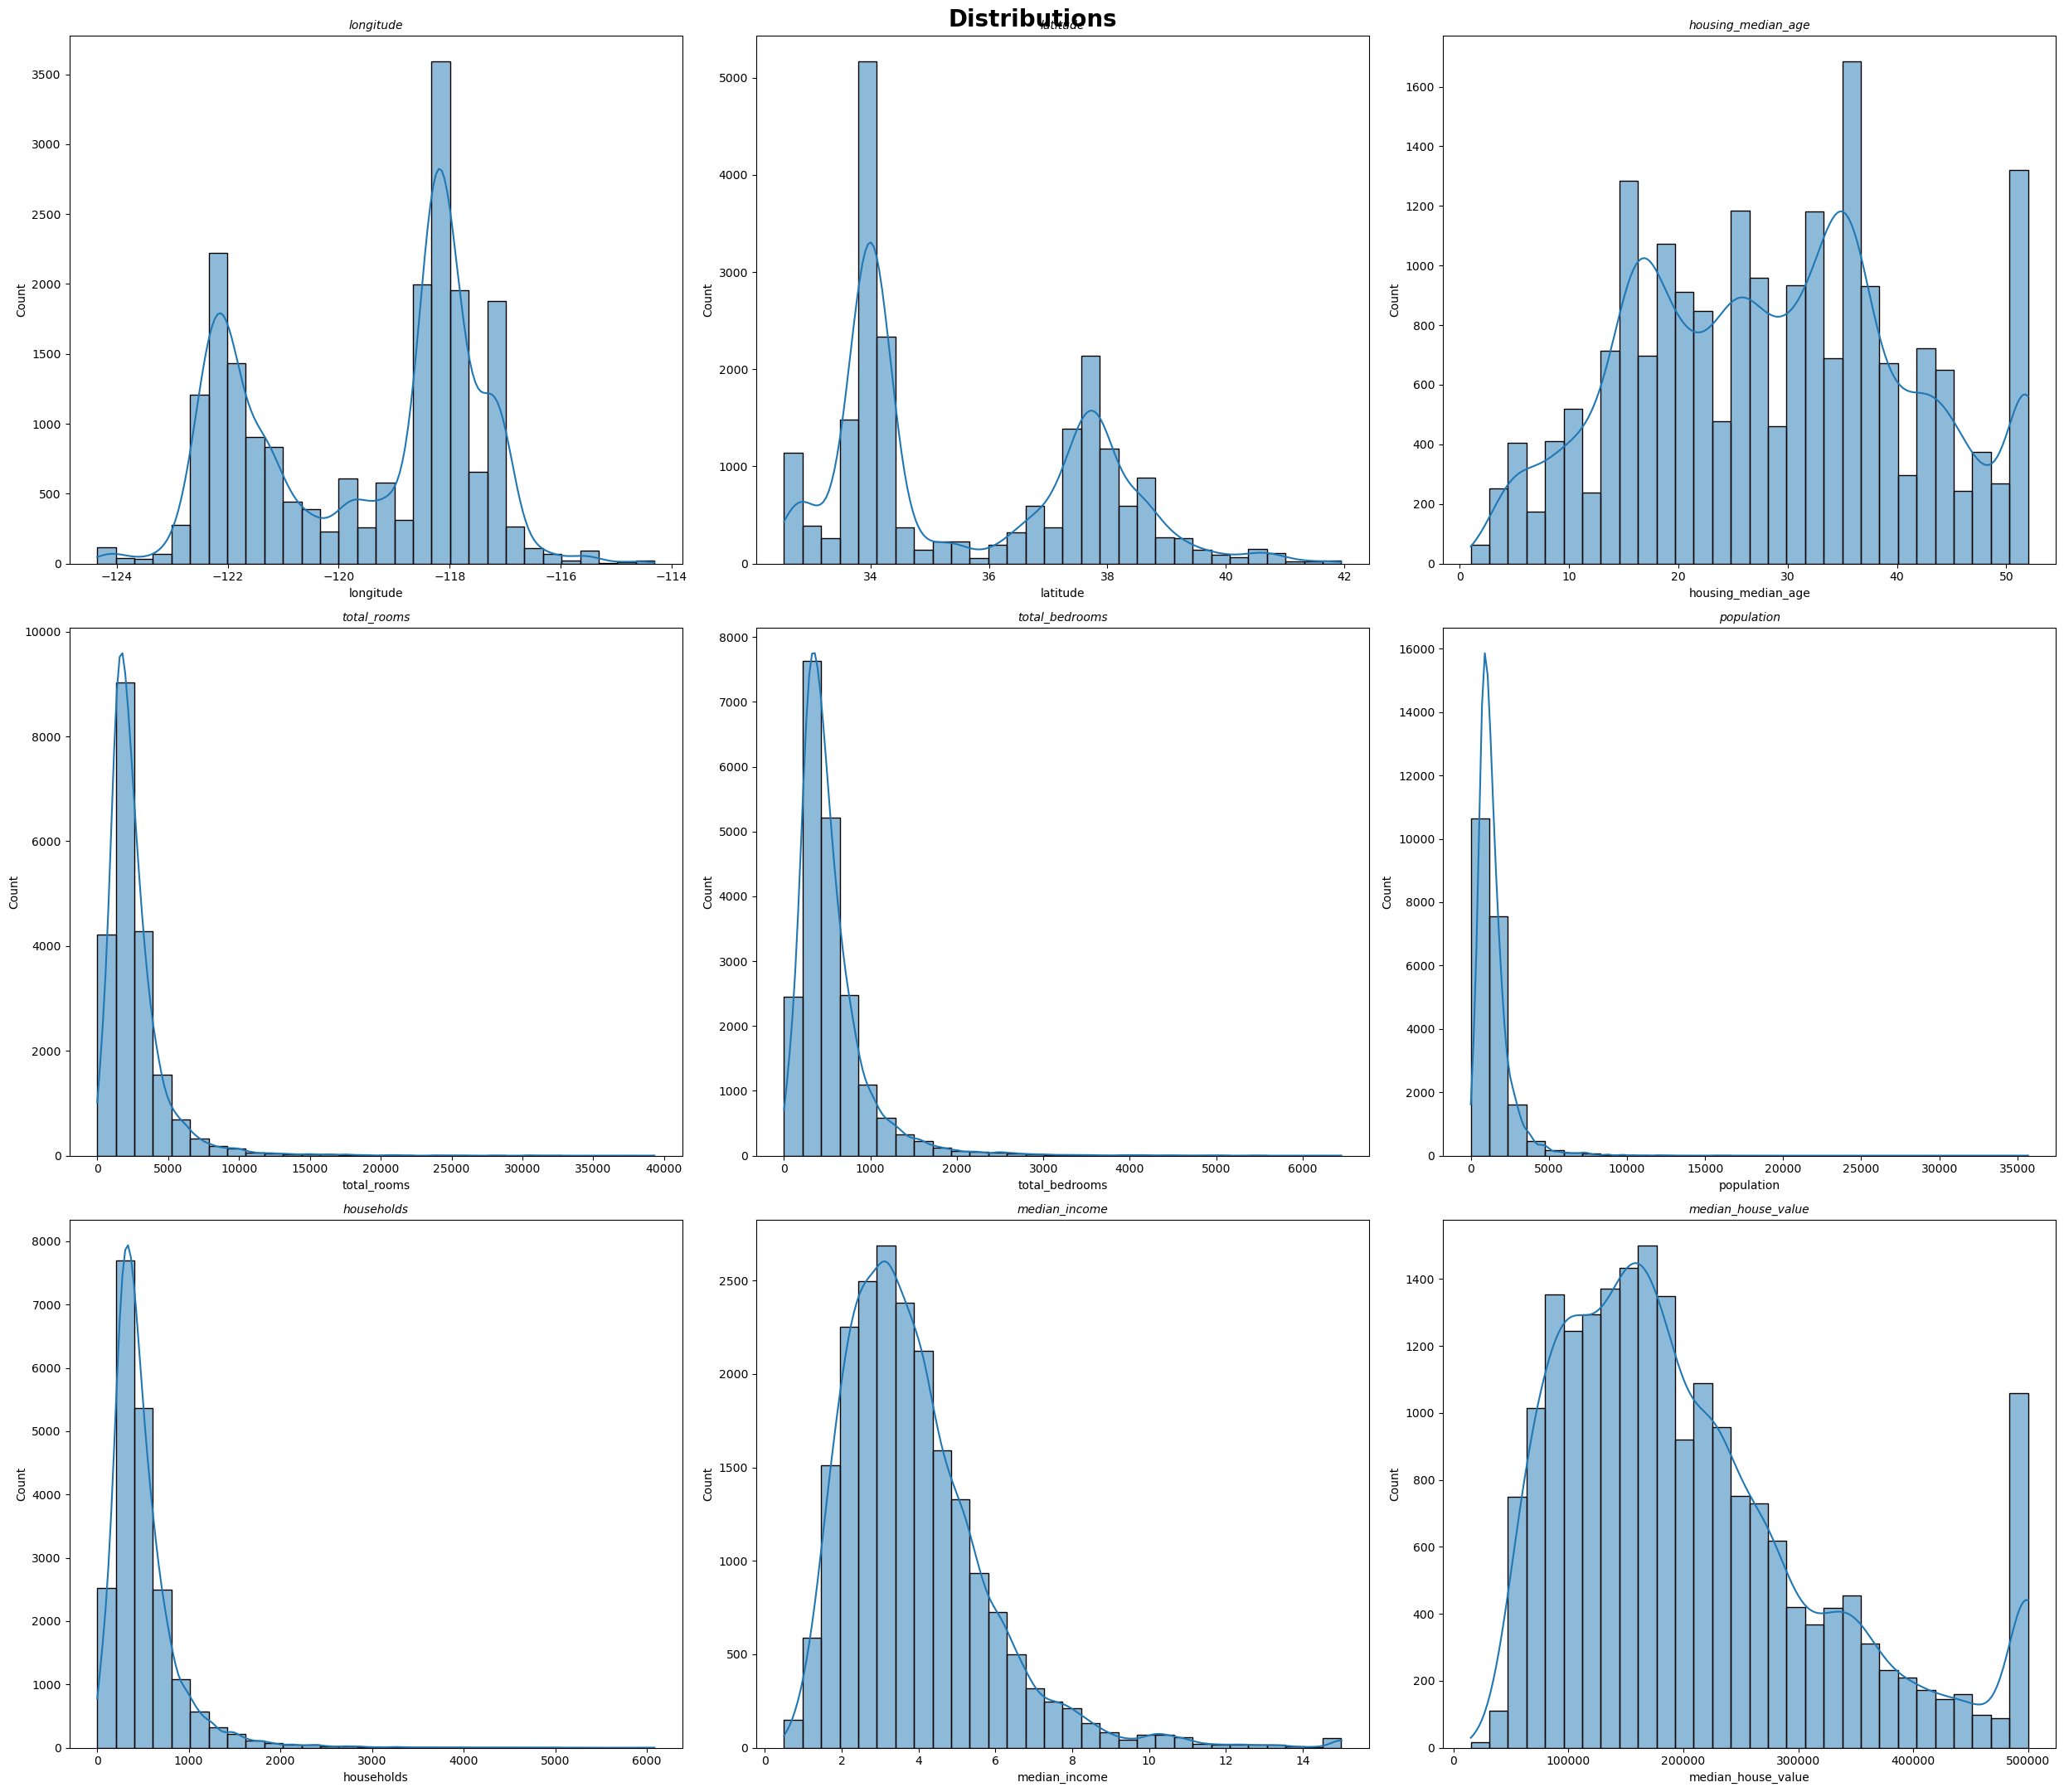

In [9]:
fig,axes = plt.subplots(nrows = 3 , ncols = 3,figsize = ( 25,22))
fig.suptitle("Distributions",fontsize = 20 ,fontweight = "bold")
axes = axes.flatten()

for i ,col in enumerate (num_cols):
    if i < len(axes):
    #prevent the error if num_cols>9
     sns.histplot(data =df,x = col,kde =True,ax=axes[i],bins = 30 )
     axes[i].set_title(col,fontsize =10, fontstyle ='italic')
plt.tight_layout()
plt.show()


In [10]:
df.corr(numeric_only=True)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


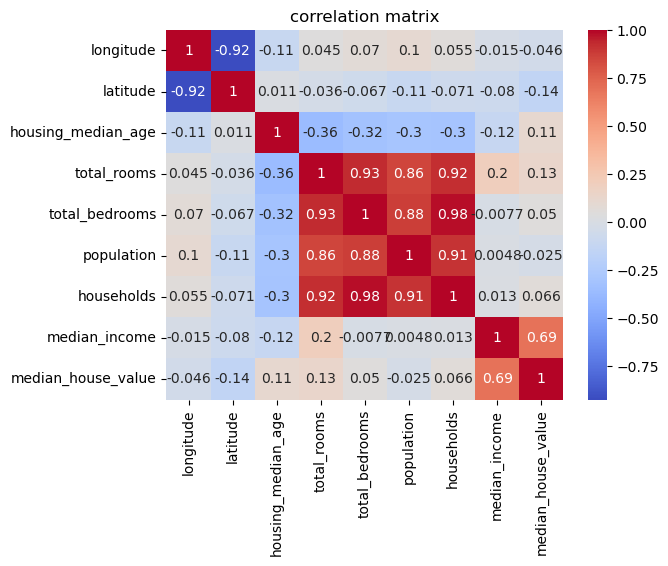

In [11]:
sns.heatmap(df.corr(numeric_only=True),annot =True,cmap="coolwarm")
plt.title('correlation matrix')
plt.show()

In [12]:
def find_outliers_iqr (df,threshold= 1.5 ):
    outliers_summary = {}
    numeric_cols = df.select_dtypes(include =['float64','int64']).columns
    for col in numeric_cols:
        Q1=df[col].quantile(0.25)
        Q3= df[col].quantile(0.75)
        IQR = Q3-Q1
        lower_bound = Q1-threshold * IQR
        upper_bound = Q3 + threshold * IQR
        outliers = df [(df[col]<lower_bound)|(df[col]>upper_bound)]
        outliers_summary[col]={
         "outliers_count" : outliers.shape[0],
         "outliers_percentage":100*outliers.shape[0]/df.shape[0],
         "lower_bound ": lower_bound,
         "uppr_bound " : upper_bound
        }
    return pd.DataFrame(outliers_summary)

In [13]:
find_outliers_iqr(df,threshold =1.5 )

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
outliers_count,0.000,0.00,0.0,1287.000000,1271.000000,1196.000000,1220.000000,681.000000,1071.000000
outliers_percentage,0.000,0.00,0.0,6.235465,6.157946,5.794574,5.910853,3.299419,5.188953
lower_bound,-127.485,28.26,-10.5,-1102.625000,-230.500000,-620.000000,-207.500000,-0.706375,-98087.500000
uppr_bound,-112.325,43.38,65.5,5698.375000,1173.500000,3132.000000,1092.500000,8.013025,482412.500000


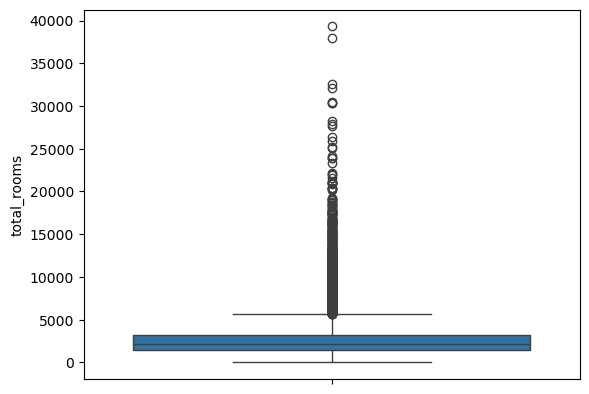

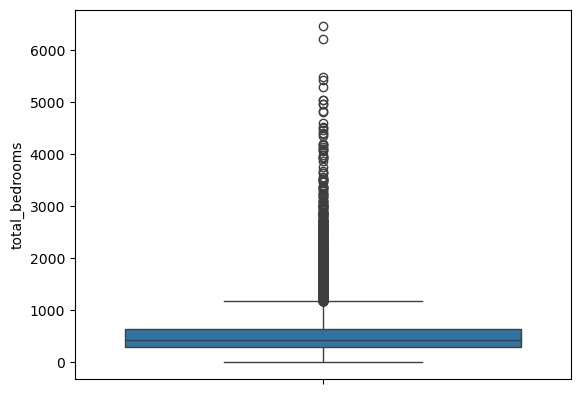

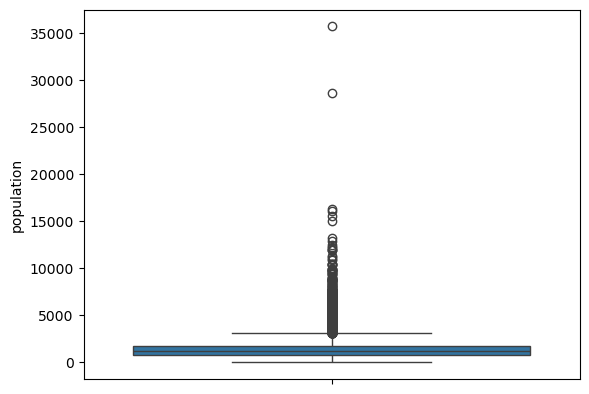

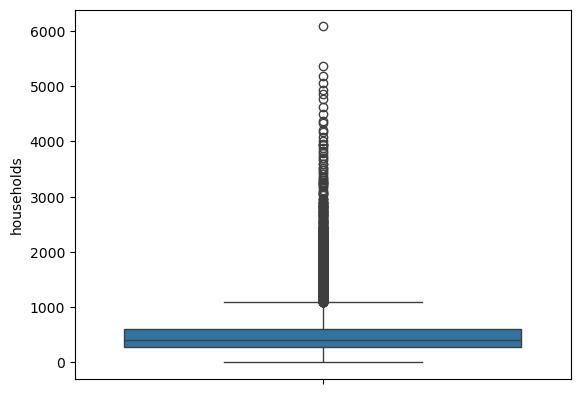

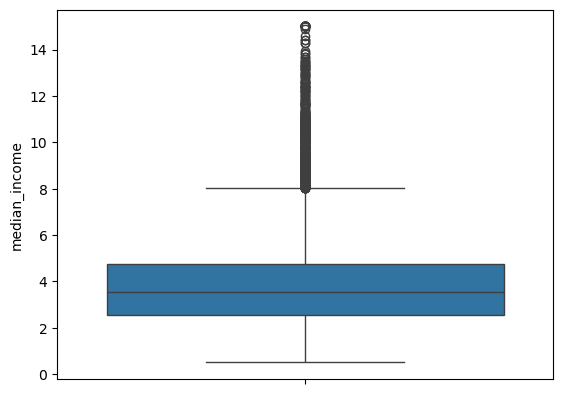

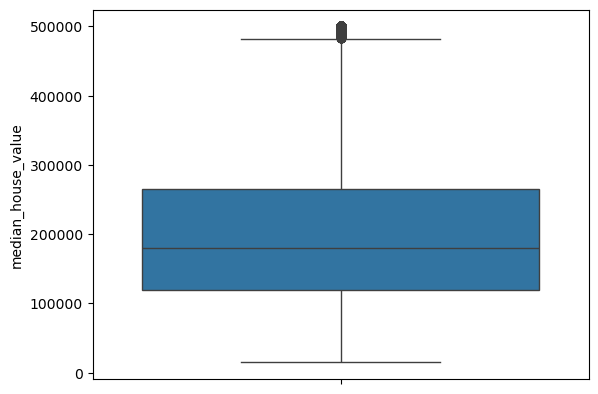

In [14]:
cols = [ 'total_rooms','total_bedrooms','population','households','median_income','median_house_value']
for i ,col in enumerate(cols):
    sns.boxplot(data = df ,y = cols [i])
    plt.show()

In [15]:
def remove_outliers_from_all_columns(df,threshold=1.0):
 df_clean = df.copy()
 numeric_cols = df.select_dtypes(include=['number']).columns
 for col in numeric_cols:
    Q1=df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3-Q1
    lower_bound = Q1-threshold*IQR
    upper_bound = Q3+threshold*IQR
    print(f"column:{col}|Bounds:{lower_bound}to{upper_bound}|Data Min/Max:{df[col].min()}/{df[col].max()}")
    df_clean = df_clean[(df_clean[col]>=lower_bound)&(df_clean[col]<=upper_bound)]
    return df_clean

In [16]:
print ('original data shape:',df.shape)
df_all_clean= remove_outliers_from_all_columns(df)
print('all columns cleaning shape:',df_all_clean.shape)

original data shape: (20640, 10)
column:longitude|Bounds:-125.58999999999999to-114.22000000000001|Data Min/Max:-124.35/-114.31
all columns cleaning shape: (20640, 10)


In [17]:
df_all_clean.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [18]:
avg_bedrooms=df_all_clean['total_bedrooms'].mean()
df_all_clean['total_bedrooms']=df_all_clean['total_bedrooms'].fillna(avg_bedrooms)
print(df_all_clean['total_bedrooms'].isnull().sum())

0


In [19]:
df_all_clean.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [20]:
print(f"Duplicate rows:{df.duplicated().sum()}")
print(df[df.duplicated(keep=False)].head())

Duplicate rows:0
Empty DataFrame
Columns: [longitude, latitude, housing_median_age, total_rooms, total_bedrooms, population, households, median_income, median_house_value, ocean_proximity]
Index: []


In [21]:
df_all_clean.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,419.266592,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,297.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,438.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [22]:
df_all_clean['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [23]:
df_final = df_all_clean.drop("ocean_proximity",axis =1 )

In [24]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20640 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [25]:
missing_cols=[col for col in num_cols if col not in df_final.columns]
print (f"missing columns:{missing_cols}")

missing columns:['ocean_proximity']


In [26]:
df_skew_check = df_final[df_final.columns.intersection(num_cols)]

In [27]:
from scipy.stats import skew

skews = df_skew_check.apply(skew).sort_values(ascending=False)
print(skews)


population            4.935500
total_rooms           4.147042
total_bedrooms        3.476771
households            3.410190
median_income         1.646537
median_house_value    0.977692
latitude              0.465919
housing_median_age    0.060326
longitude            -0.297780
dtype: float64


In [28]:
from sklearn.preprocessing import PowerTransformer

X = df_final.drop('median_house_value', axis = 1)
y = df_final['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=15)


In [29]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16512 entries, 437 to 7624
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           16512 non-null  float64
 1   latitude            16512 non-null  float64
 2   housing_median_age  16512 non-null  float64
 3   total_rooms         16512 non-null  float64
 4   total_bedrooms      16512 non-null  float64
 5   population          16512 non-null  float64
 6   households          16512 non-null  float64
 7   median_income       16512 non-null  float64
dtypes: float64(8)
memory usage: 1.1 MB


In [30]:
pt_X = PowerTransformer(method = 'yeo-johnson')
X_train_transformed = pt_X.fit_transform(X_train)
X_train_transformed=pt_X.transform(X_test)

In [31]:
X_train_transformed

array([[-5.27355937e-16,  1.04977221e+00,  1.75013252e+00, ...,
        -4.36364526e-01, -2.74584339e-01, -3.54984440e-01],
       [-4.99600361e-16,  1.04300713e+00,  6.00479460e-01, ...,
        -1.17110749e+00, -1.32730458e+00, -1.27220325e+00],
       [ 2.77555756e-16, -4.07038682e-01, -1.53371434e+00, ...,
         5.14670158e-01,  3.49538399e-01,  2.16468505e-01],
       ...,
       [ 2.22044605e-16, -7.08358763e-01,  3.75050788e-01, ...,
         1.08721155e+00,  7.46212750e-01, -8.04034930e-01],
       [ 4.71844785e-16, -4.18824652e-01, -9.06719723e-01, ...,
         5.50545155e-01,  5.27945416e-01,  8.23992102e-01],
       [-5.27355937e-16,  1.04977221e+00,  1.75013252e+00, ...,
         2.07513024e-01,  8.24462165e-01,  4.88025115e-01]])

In [32]:
import math

def plot_all_histograms(df, title_prefix=""):
    num_cols = df.select_dtypes(include=[np.number]).columns
    n_cols = 3
    n_rows = math.ceil(len(num_cols) / n_cols)

    plt.figure(figsize=(5 * n_cols, 4 * n_rows))

    for i, col in enumerate(num_cols, 1):
        plt.subplot(n_rows, n_cols, i)
        sns.histplot(df[col], kde=True, bins=30)
        plt.title(f"{title_prefix}{col}")
        plt.xlabel("")
        plt.ylabel("")

    plt.tight_layout()
    plt.show()


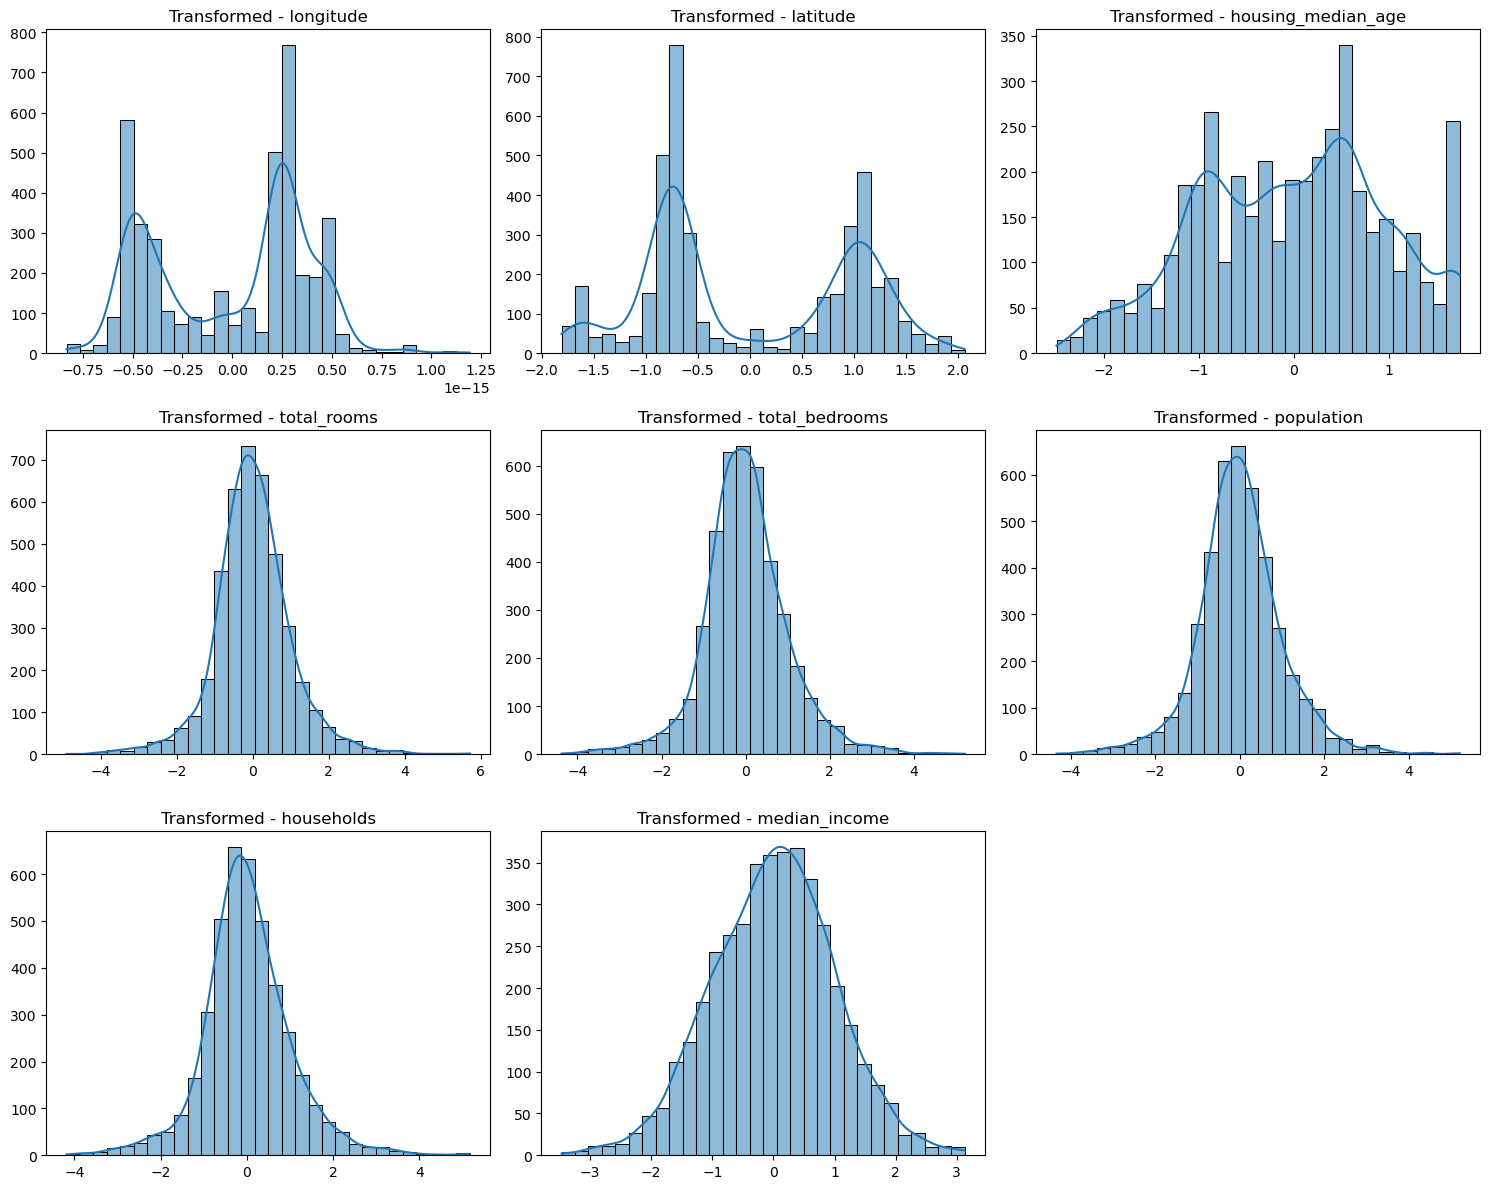

In [33]:
X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = X_train.columns)
plot_all_histograms(X_train_transformed_df, title_prefix="Transformed - ")
